In [162]:
#!pip install micromlgen

In [1]:
import pandas as pd
import numpy as np
from itertools import chain
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from micromlgen import port

ModuleNotFoundError: No module named 'micromlgen'

In [29]:
# Load Data
data = pd.read_csv("Project 1 - Weather Dataset.csv")

In [30]:
def create_list(category) -> list:
    list_of_lists = [w.split() for w in category.split(',')]
    flat_list = list(chain(*list_of_lists))
    return flat_list

def get_weather(list1):
    if 'Fog' in list1 and 'Rain' in list1: return 'RAIN + FOG'
    elif 'Snow' in list1 and 'Rain' in list1: return 'SNOW'
    elif 'Snow' in list1: return 'SNOW'
    elif 'Fog' in list1: return 'FOG'
    elif 'Clear' in list1: return 'Clear'
    elif 'Cloudy' in list1: return 'Cloudy'
    elif 'Thunderstorms' in list1: return 'Thunderstorms'
    elif 'Moderate' in list1: return 'Moderate'
    else: return 'RAIN'

data['std_Weather'] = data['Weather'].apply(lambda c: get_weather(create_list(c)))

In [31]:
data.head()

,Date/Time,Temp_C,Dew Point Temp_C,Rel Hum_%,Wind Speed_km/h,Visibility_km,Press_kPa,Weather,std_Weather
0,1/1/2012 0:00,-1.8,-3.9,86,4,8.0,101.24,Fog,FOG
1,1/1/2012 1:00,-1.8,-3.7,87,4,8.0,101.24,Fog,FOG
2,1/1/2012 2:00,-1.8,-3.4,89,7,4.0,101.26,"Freezing Drizzle,Fog",FOG
3,1/1/2012 3:00,-1.5,-3.2,88,6,4.0,101.27,"Freezing Drizzle,Fog",FOG
4,1/1/2012 4:00,-1.5,-3.3,88,7,4.8,101.23,Fog,FOG


In [32]:
data.std_Weather.value_counts()

std_Weather
Cloudy           3797
Clear            3432
SNOW              582
RAIN              581
FOG               241
RAIN + FOG        129
Thunderstorms      22
Name: count, dtype: int64

In [33]:
cloudy_df = data[data['std_Weather'] == 'Cloudy'].sample(582)
print(f"Cloudy dataset: {cloudy_df.shape}")
clear_df = data[data['std_Weather'] == 'Clear'].sample(582)
print(f"Clear dataset: {clear_df.shape}")
snow_df = data[data['std_Weather'] == 'SNOW'].sample(582)
print(f"Snow dataset: {snow_df.shape}")
rain_df = data[data['std_Weather'] == 'RAIN'].sample(581)
print(f"Rain dataset: {rain_df.shape}")

Cloudy dataset: (582, 9)
Clear dataset: (582, 9)
Snow dataset: (582, 9)
Rain dataset: (581, 9)


In [34]:
data = pd.concat([cloudy_df,clear_df,snow_df,rain_df],axis=0)

In [35]:
data.head()

,Date/Time,Temp_C,Dew Point Temp_C,Rel Hum_%,Wind Speed_km/h,Visibility_km,Press_kPa,Weather,std_Weather
6647,10/3/2012 23:00,18.0,14.9,82,7,25.0,101.57,Cloudy,Cloudy
3064,5/7/2012 16:00,20.9,-2.0,21,11,48.3,101.14,Mostly Cloudy,Cloudy
2745,4/24/2012 9:00,7.7,1.4,64,17,48.3,98.64,Mostly Cloudy,Cloudy
5436,8/14/2012 12:00,22.6,18.5,78,9,24.1,100.84,Cloudy,Cloudy
4067,6/18/2012 11:00,24.0,14.9,57,19,24.1,101.14,Mostly Cloudy,Cloudy


In [36]:
data.to_csv('my_output.csv', index=False)

In [37]:
data.shape

(2327, 9)

In [38]:
data.drop(columns=['Weather','Wind Speed_km/h','Visibility_km'], inplace=True)
data.head()

,Date/Time,Temp_C,Dew Point Temp_C,Rel Hum_%,Press_kPa,std_Weather
6647,10/3/2012 23:00,18.0,14.9,82,101.57,Cloudy
3064,5/7/2012 16:00,20.9,-2.0,21,101.14,Cloudy
2745,4/24/2012 9:00,7.7,1.4,64,98.64,Cloudy
5436,8/14/2012 12:00,22.6,18.5,78,100.84,Cloudy
4067,6/18/2012 11:00,24.0,14.9,57,101.14,Cloudy


In [39]:
FEATURES = ['Temp_C', 'Dew Point Temp_C', 'Rel Hum_%','Press_kPa']
TARGET = 'std_Weather'

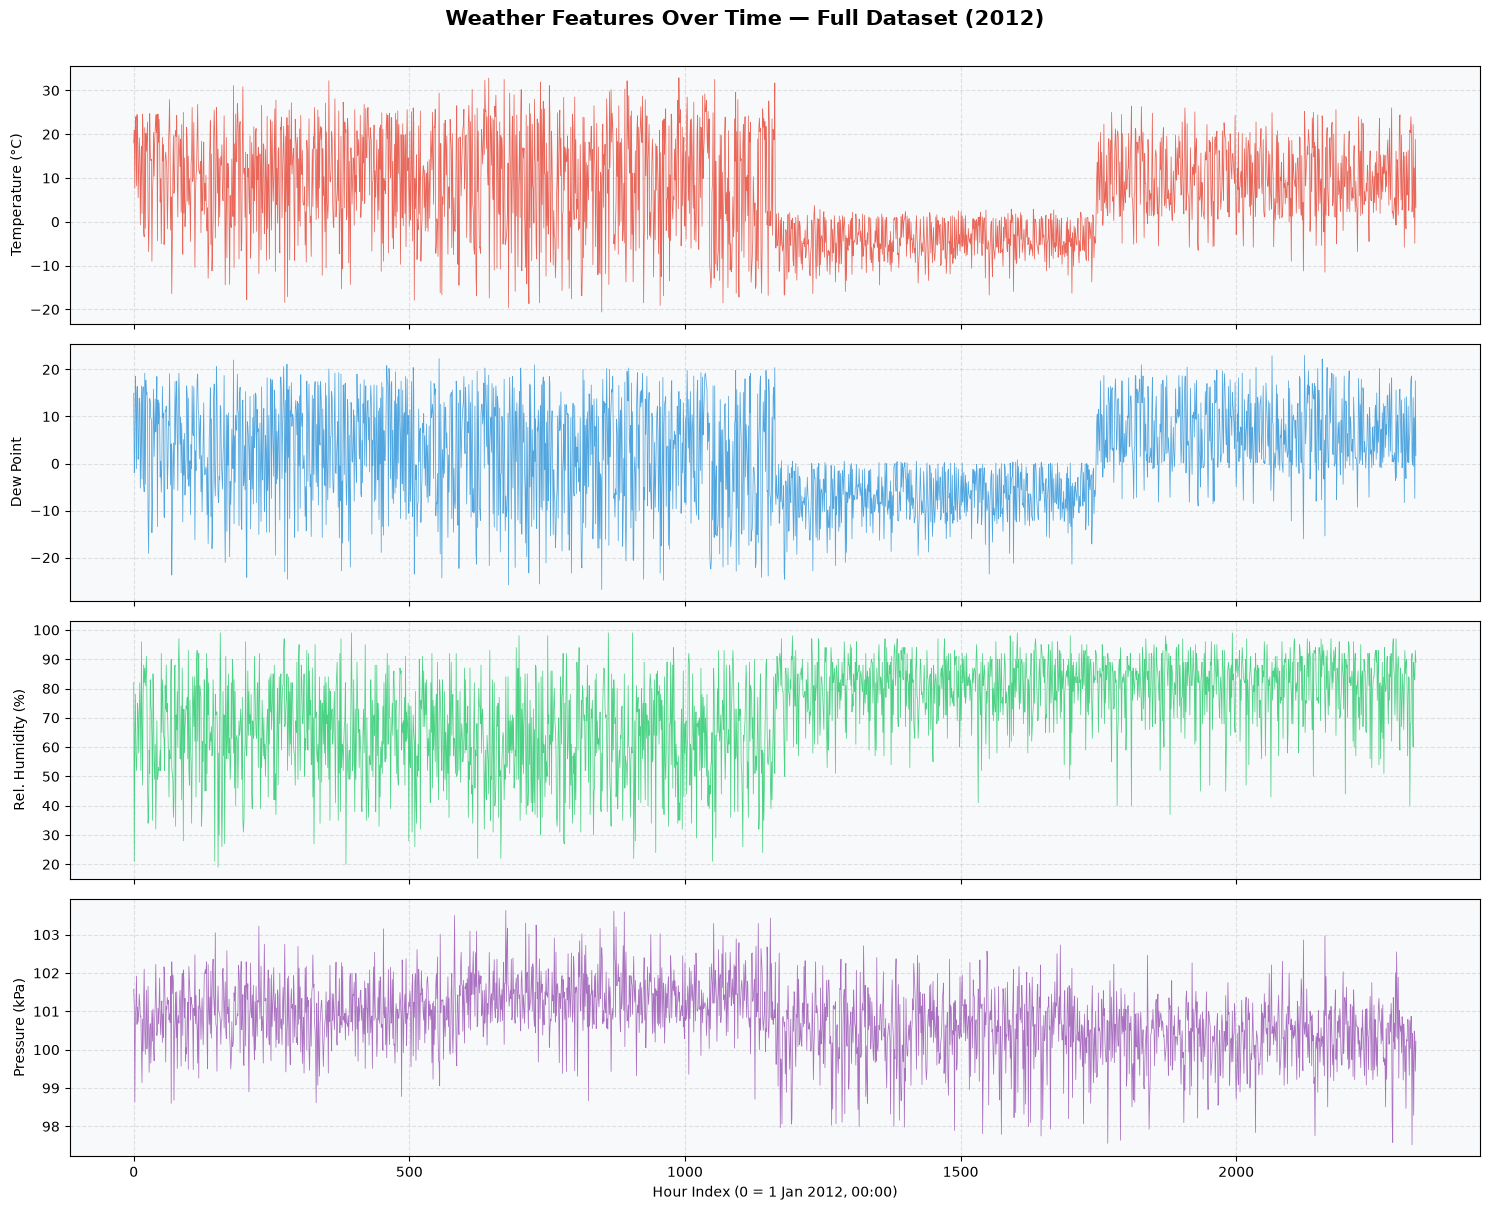

In [40]:
# ── Time-series plots for all four features ───────────────────────────────────
COLORS  = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
YLABELS = ['Temperature (°C)', 'Dew Point', 'Rel. Humidity (%)', 'Pressure (kPa)']

fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)
fig.suptitle('Weather Features Over Time — Full Dataset (2012)',
             fontsize=15, fontweight='bold', y=1.005)

for ax, col, color, ylabel in zip(axes, FEATURES, COLORS, YLABELS):
    ax.plot(data[col].values, color=color, linewidth=0.55, alpha=0.85)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_facecolor('#f8f9fa')
    ax.grid(True, linestyle='--', alpha=0.35)

axes[-1].set_xlabel('Hour Index (0 = 1 Jan 2012, 00:00)', fontsize=10)
plt.tight_layout()
#plt.savefig('features_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

In [60]:
# Features and Target
X = data[FEATURES]
y = data[TARGET]

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 70% train, 30% test split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

print(f"X-Train Shape: {X_train.shape} and X-test Shape: {X_test.shape}")
print(f"Y-Train Shape: {y_train.shape} and Y-test Shape: {y_test.shape}")

# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)


X-Train Shape: (1861, 4) and X-test Shape: (466, 4)
Y-Train Shape: (1861,) and Y-test Shape: (466,)


In [61]:
model = RandomForestClassifier( n_estimators=25, max_depth=8, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",25
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: 

In [62]:
# FIXED: Removed trailing comma
#model = RandomForestClassifier(n_estimators=100, random_state=42)
#model = RandomForestClassifier( n_estimators=10, max_depth=6, min_samples_leaf=6, random_state=42)

#model.fit(X_train, y_train)

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Random Forest accuracy: {acc:.4f}")

Random Forest accuracy: 0.6502


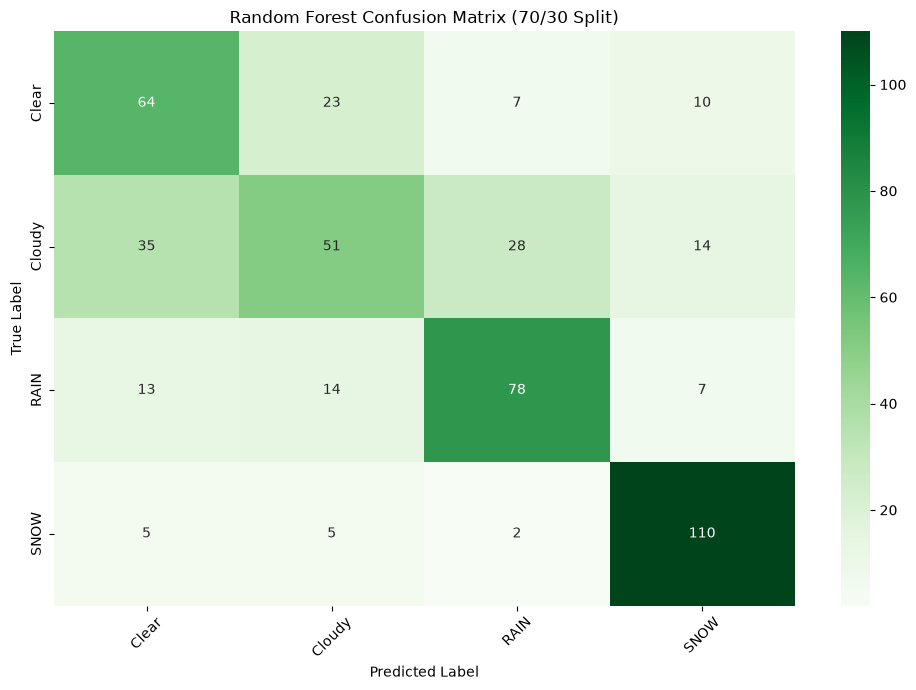

In [63]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
target_names = le.inverse_transform(np.unique(y_test))

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=target_names, 
            yticklabels=target_names)
plt.title('Random Forest Confusion Matrix (70/30 Split)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [64]:
class_map = {idx: label for idx, label in enumerate(le.classes_)}
c_code = port(model, classmap=class_map)

with open('WeatherModel.h', 'w') as file:
    file.write(c_code)

print("Saved 'WeatherModel.h' successfully!")

Saved 'WeatherModel.h' successfully!


In [66]:
test_values = [[34.94, 26.88, 63.21, 98.10]]

# 6. Predict and decode the result
prediction_encoded = model.predict(test_values)
predicted_weather = le.inverse_transform(prediction_encoded)[0]

print(f"Predicted Output: {predicted_weather}")

Predicted Output: Clear


D:\PRIMAL\Documents\Qiskit\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
